**Live cloud deployment:** [Open Heart Disease predictor](https://abeera-sp24-bse-004-heart.streamlit.app/)

**Abeera | SP24-BSE-004** — public cloud predictions verified on 22 October 2026 (Asia/Karachi). Default and changed-input cases matched the saved local model. See `../deployment_status.json` and deployment evidence.

# Heart Disease Prediction System
**Abeera | SP24-BSE-004**  
AIC354 - Machine Learning Fundamentals | Assignment 2 | Fall 2026  
COMSATS University Islamabad, Lahore Campus  
Instructor: Dr. Rao Muhammad Adeel Nawab

This notebook follows the supplied Titanic workflow: data collection, understanding,
preprocessing, feature selection, label encoding, training, testing, application,
feedback and deployment. Run all cells in order to recreate the saved model and app.

## Sources and execution
The assignment explicitly provides the [instructor's teaching repository](https://github.com/haqnawaz99/ml-teaching-notebooks).
Its Titanic Recommended notebook credits Mr. Mohsin Afzal and Dr. Rao Muhammad Adeel Nawab.
The same numbered learning steps and Support Vector Classifier are used here, with fresh
analysis, validation and a separate interface prepared for Abeera.

Repository for this submission: [https://github.com/Abeera0802/aic354-assignment2](https://github.com/Abeera0802/aic354-assignment2).
Source commit and dataset hashes are in `../PROVENANCE.json`.
The implementation was prepared with AI assistance and checked by executing the notebooks.
Review and understand the cells before submission.

Install `../requirements-notebook.txt` with Python 3.14. Open this notebook from its
task folder, the submission folder or the Abeera workspace; choose **Restart Kernel and Run All Cells**.
All source data are included, so training works offline.

## Task definition and four-input decision
Use only the processed Cleveland part of the UCI Heart Disease dataset. The recorded
target `num=0` means absence; `num=1,2,3,4` is mapped to presence. `num` is never an input.

Four attributes are selected **before evaluating the model**: `age`, `cp`, `thalach`,
and `oldpeak`. They cover age, symptom category, exercise heart rate and exercise-related
ST depression. This is an interpretable classroom choice, not a claim of optimal features.
No fifth attribute is used at training or prediction time.

The teaching steps and SVC are retained. Dataset-specific adaptations are `?` handling,
a binary target, a stratified 80/20 split with seed 4, and training-only imputation/scaling.
Only categorical `cp` is label encoded; numerical measurements retain their meaning.

Dataset citation: Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1989).
*Heart Disease*. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X.
License: CC BY 4.0. This experiment is not a medical diagnostic tool.

## Step 1: Import libraries

In [1]:
from pathlib import Path
import hashlib, json, pickle, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, balanced_accuracy_score)

TASK = 'Heart_Disease'
candidates = [Path.cwd(), Path.cwd() / TASK,
              Path.cwd() / 'SP24-BSE-004_Abeera_ML_Assignment_2' / TASK]
BASE = next((p for p in candidates if (p / 'data').is_dir() and p.name == TASK), None)
assert BASE is not None, 'Open from this task folder, the submission folder, or the Abeera workspace.'
for folder in ['models', 'outputs']:
    (BASE / folder).mkdir(exist_ok=True)
pd.set_option('display.max_rows', 12)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Abeera | SP24-BSE-004 |', TASK)
print('Python', platform.python_version(), '| scikit-learn', sklearn.__version__)

Abeera | SP24-BSE-004 | Heart_Disease
Python 3.14.6 | scikit-learn 1.9.1


## Step 2: Load sample data

The original source file is included. Its SHA256 makes data provenance checkable.

In [2]:
columns = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal','num']
source_file = BASE / 'data/processed.cleveland.data'
# Data are bundled for offline execution. Re-download from UCI if absent.
if not source_file.exists():
    from io import BytesIO
    from urllib.request import urlopen
    from zipfile import ZipFile
    with urlopen('https://archive.ics.uci.edu/static/public/45/heart+disease.zip', timeout=60) as response:
        with ZipFile(BytesIO(response.read())) as archive:
            source_file.write_bytes(archive.read('processed.cleveland.data'))
raw = pd.read_csv(source_file, names=columns, na_values='?')
assert raw.shape == (303, 14)
raw.to_csv(BASE / 'data/heart_cleveland.csv', index=False)

In [3]:
print('Source rows / columns:', raw.shape)
print('SHA256:', hashlib.sha256(source_file.read_bytes()).hexdigest())
display(raw.head(8))

Source rows / columns: (303, 14)
SHA256: a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
5,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0
6,62.0,0.0,4.0,140.0,268.0,0.0,2.0,160.0,0.0,3.6,3.0,2.0,3.0,3
7,57.0,0.0,4.0,120.0,354.0,0.0,0.0,163.0,1.0,0.6,1.0,0.0,3.0,0


## Step 3: Understand and preprocess sample data
### 3.1 Understand the records

In [4]:
raw.info()
display(raw.describe(include='all'))
display(raw.isna().sum().to_frame('Missing values'))
print('Repeated full rows:', int(raw.duplicated().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


,Missing values
age,0
sex,0
cp,0
trestbps,0
chol,0
...,...
oldpeak,0
slope,0
ca,4
thal,2


Repeated full rows: 0


### 3.2 Preprocess the records
`?` becomes missing during loading. Inspect missingness across all columns; a missing value
in an unused column is not grounds to drop a record. Validate the target before mapping
it to binary labels. Imputation statistics will be fitted on training data only.

In [5]:
assert raw['num'].notna().all()
assert set(raw['num'].unique()) <= {0, 1, 2, 3, 4}
raw['Disease'] = (raw['num'] > 0).astype(int)
display(raw[['num','Disease']].drop_duplicates().sort_values('num'))

,num,Disease
0,0,0
2,1,1
1,2,1
6,3,1
24,4,1


## Step 4: Feature extraction / selection

Keep the target separate and lock the four feature names and their order.

In [6]:
FEATURES = ['age', 'cp', 'thalach', 'oldpeak']
TARGET = 'Disease'
assert len(FEATURES) == 4 and TARGET not in FEATURES and 'num' not in FEATURES
sample = raw[FEATURES + [TARGET]].copy()
sample.to_csv(BASE / 'data/four_inputs.csv', index=False)
display(sample.head())
display(sample.isna().sum().to_frame('Missing selected values'))

,age,cp,thalach,oldpeak,Disease
0,63.0,1.0,150.0,2.3,0
1,67.0,4.0,108.0,1.5,1
2,67.0,4.0,129.0,2.6,1
3,37.0,3.0,187.0,3.5,0
4,41.0,2.0,172.0,1.4,0


,Missing selected values
age,0
cp,0
thalach,0
oldpeak,0
Disease,0


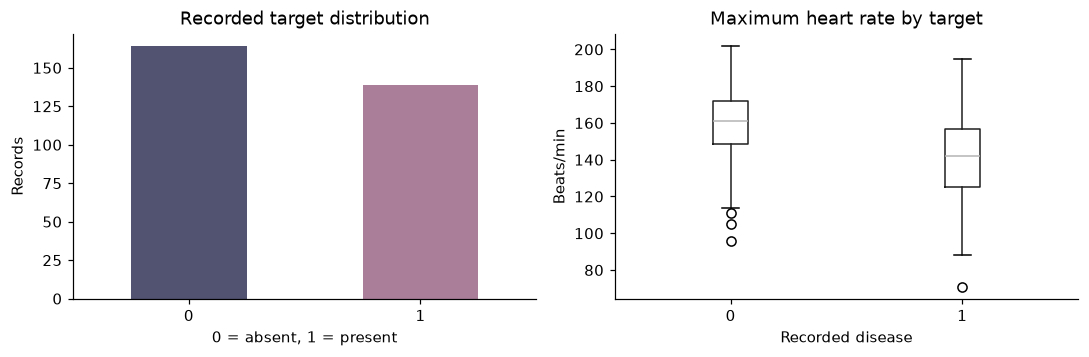

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sample['Disease'].value_counts().sort_index().plot.bar(ax=axes[0], color=['#525271','#aa7d99'], rot=0)
axes[0].set(title='Recorded target distribution', xlabel='0 = absent, 1 = present', ylabel='Records')
sample.boxplot(column='thalach', by='Disease', ax=axes[1], grid=False)
axes[1].set(title='Maximum heart rate by target', xlabel='Recorded disease', ylabel='Beats/min')
fig.suptitle('')
plt.tight_layout()
fig.savefig(BASE / 'outputs/data_overview.png', bbox_inches='tight')
plt.show()

## Step 5: Label encoding
### 5.1 Fit encoders; 5.2 encode output; 5.3 encode inputs
The category vocabularies are fixed by the dataset definitions, not learned from the
held-out labels. `LabelEncoder` sorts labels. For Titanic this means Sibling codes are
One=0, Three=1, Two=2, Zero=3; they are not sibling counts. For Heart Disease `cp` codes
1-4 map to 0-3, and `num > 0` supplies the binary target. Numeric measurements are not
converted into arbitrary category labels. These encoders will be saved for inference.

In [8]:
category_schema = {'cp': [1, 2, 3, 4]}
encoders = {name: LabelEncoder().fit(categories) for name, categories in category_schema.items()}
encoded = sample.copy()
for name, encoder in encoders.items():
    assert set(sample[name].dropna()) <= set(encoder.classes_)
    mask = sample[name].notna()
    encoded[name] = np.nan
    encoded.loc[mask, name] = encoder.transform(sample.loc[mask, name])
    print(name, dict(zip(encoder.classes_.tolist(), range(len(encoder.classes_)))))
encoded[TARGET] = sample[TARGET].astype(int)
encoded.to_csv(BASE / 'outputs/encoded_data.csv', index_label='source_row')
display(encoded.head(8))

cp {1: 0, 2: 1, 3: 2, 4: 3}


,age,cp,thalach,oldpeak,Disease
0,63.0,0.0,150.0,2.3,0
1,67.0,3.0,108.0,1.5,1
2,67.0,3.0,129.0,2.6,1
3,37.0,2.0,187.0,3.5,0
4,41.0,1.0,172.0,1.4,0
5,56.0,1.0,178.0,0.8,0
6,62.0,3.0,160.0,3.6,1
7,57.0,3.0,163.0,0.6,0


## Step 6: Execute the training phase
### 6.1 Split; 6.2 separate input vectors and labels
The heart dataset uses a fixed stratified 80/20 split (seed 4, chosen before evaluation).
Titanic reproduces the instructor's ordered 80/20 split. Test rows are reserved for final
evaluation, not parameter or feature selection. Source row indices are retained for audit.

In [9]:
train_idx, test_idx = train_test_split(encoded.index, test_size=0.2, stratify=encoded[TARGET], random_state=4)
X_train, X_test = encoded.loc[train_idx, FEATURES], encoded.loc[test_idx, FEATURES]
y_train, y_test = encoded.loc[train_idx, TARGET], encoded.loc[test_idx, TARGET]
assert set(train_idx).isdisjoint(test_idx)
assert len(train_idx) + len(test_idx) == len(sample)
assert X_train.shape[1] == X_test.shape[1] == 4
for indices, name in [(train_idx, 'train'), (test_idx, 'test')]:
    encoded.loc[indices].to_csv(BASE / f'outputs/{name}_data.csv', index_label='source_row')
display(pd.DataFrame({'Training': y_train.value_counts(), 'Testing': y_test.value_counts()}).sort_index())

,Training,Testing
Disease,,
0,131,33
1,111,28


### 6.3 Train the Support Vector Classifier
Retain the teaching SVC settings: RBF kernel, C=1, gamma='auto', random_state=0.
Heart Disease also needs imputation/scaling because ages, heart rates and ST depression
have different numerical units. The pipeline fits those statistics only on training rows.
No test-based tuning is performed.

In [10]:
model = Pipeline([('impute', SimpleImputer(strategy='median')),
                  ('scale', StandardScaler()),
                  ('svc', SVC(gamma='auto', random_state=0))])
model.fit(X_train, y_train)
print(model)
np.testing.assert_allclose(model.named_steps['impute'].statistics_, X_train.median().to_numpy())

Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('scale', StandardScaler()),
                ('svc', SVC(gamma='auto', random_state=0))])


### 6.4 Save the trained model

Save feature order, encoders, labels, metadata and fitted estimator together. Only load trusted pickle files.

In [11]:
bundle = {'student': 'Abeera', 'registration': 'SP24-BSE-004', 'task': TASK,
          'features': FEATURES, 'encoders': encoders, 'model': model,
          'labels': {0: 'Recorded disease absent', 1: 'Recorded disease present'}, 'source_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease',
          'sklearn_version': sklearn.__version__, 'feature_guide': [{'Attribute': 'age', 'Meaning': 'Age in years', 'Type': 'Numerical'}, {'Attribute': 'cp', 'Meaning': '1 typical angina; 2 atypical; 3 non-anginal pain; 4 asymptomatic', 'Type': 'Categorical'}, {'Attribute': 'thalach', 'Meaning': 'Maximum heart rate achieved (beats/min)', 'Type': 'Numerical'}, {'Attribute': 'oldpeak', 'Meaning': 'ST depression induced by exercise relative to rest (UCI definition)', 'Type': 'Numerical'}],
          'limitation': 'A small historical sample from one hospital and only four attributes cannot establish clinical usefulness. The ordinal chest-pain codes impose artificial distances; independent validation and a comparison with one-hot coding are needed.',
          'training_ranges': {name: [float(sample.loc[train_idx, name].min()), float(sample.loc[train_idx, name].max())]
                              for name in ['age', 'thalach', 'oldpeak']}}
model_file = BASE / 'models/model_bundle.pkl'
with model_file.open('wb') as stream:
    pickle.dump(bundle, stream)
print('Saved', model_file.name)

Saved model_bundle.pkl


## Step 7: Execute the testing phase
### 7.1 Separate test inputs/labels; 7.2 reload; 7.3 predict; 7.4 accuracy; 7.5 detailed metrics
Test inputs contain exactly the declared four columns. Reloading must give identical predictions.
Class 1 is the positive class. A training-majority classifier provides a simple baseline;
ROC AUC uses decision scores, not probabilities.

,Measured value
accuracy,0.819672
precision,0.840000
recall,0.750000
f1,0.792453
balanced_accuracy,0.814394
roc_auc,0.918831
baseline_accuracy,0.540984
train_rows,242.000000
test_rows,61.000000


                          precision    recall  f1-score   support

 Recorded disease absent       0.81      0.88      0.84        33
Recorded disease present       0.84      0.75      0.79        28

                accuracy                           0.82        61
               macro avg       0.82      0.81      0.82        61
            weighted avg       0.82      0.82      0.82        61



,age,cp,thalach,oldpeak,Disease,Actual_class,Predicted_class,Correct
124,65.0,1.0,174.0,1.4,1,1,0,False
160,46.0,2.0,156.0,0.0,0,0,0,True
178,43.0,3.0,162.0,1.9,0,0,0,True
99,48.0,4.0,186.0,0.0,0,0,0,True
186,42.0,3.0,194.0,0.8,0,0,0,True
113,43.0,4.0,136.0,3.0,1,1,1,True
174,64.0,4.0,132.0,2.0,1,1,1,True
169,45.0,2.0,138.0,0.0,0,0,0,True
285,58.0,4.0,140.0,4.4,1,1,1,True
210,37.0,3.0,170.0,0.0,0,0,0,True


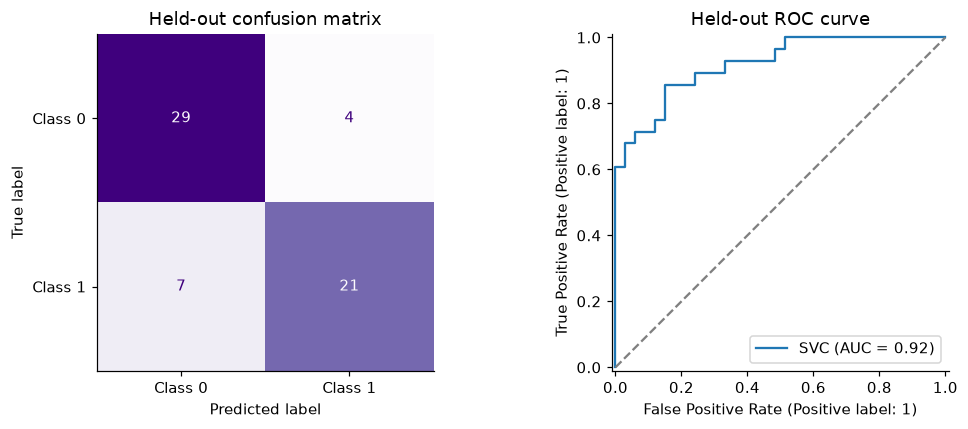

**Interpretation:** 50/61 correct (82.0%), compared with 54.1% majority baseline. False positives=4; false negatives=7. Positive recall=75.0%. These describe this fixed test split, not guaranteed future accuracy.

In [12]:
with model_file.open('rb') as stream:
    saved = pickle.load(stream)
predicted = saved['model'].predict(X_test)
np.testing.assert_array_equal(predicted, model.predict(X_test))
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
decision = saved['model'].decision_function(X_test)
metrics = {
    'accuracy': float(accuracy_score(y_test, predicted)),
    'precision': float(precision_score(y_test, predicted, zero_division=0)),
    'recall': float(recall_score(y_test, predicted, zero_division=0)),
    'f1': float(f1_score(y_test, predicted, zero_division=0)),
    'balanced_accuracy': float(balanced_accuracy_score(y_test, predicted)),
    'roc_auc': float(roc_auc_score(y_test, decision)),
    'baseline_accuracy': float(accuracy_score(y_test, baseline.predict(X_test))),
    'train_rows': len(train_idx), 'test_rows': len(test_idx),
    'confusion_matrix': confusion_matrix(y_test, predicted, labels=[0,1]).tolist()
}
display(pd.Series({k:v for k,v in metrics.items() if k != 'confusion_matrix'}, name='Measured value').to_frame())
print(classification_report(y_test, predicted, labels=[0,1], target_names=list(bundle['labels'].values()), zero_division=0))
comparisons = sample.loc[test_idx].copy()
comparisons['Actual_class'] = y_test
comparisons['Predicted_class'] = predicted
comparisons['Correct'] = y_test.to_numpy() == predicted
comparisons.to_csv(BASE / 'outputs/test_predictions.csv', index_label='source_row')
display(comparisons.head(10))
(BASE / 'outputs/metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
bundle['metrics'] = metrics
with model_file.open('wb') as stream:
    pickle.dump(bundle, stream)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=[0,1], display_labels=['Class 0','Class 1'], ax=axes[0], colorbar=False, cmap='Purples')
axes[0].set_title('Held-out confusion matrix')
RocCurveDisplay.from_predictions(y_test, decision, ax=axes[1], name='SVC')
axes[1].plot([0,1], [0,1], '--', color='gray')
axes[1].set_title('Held-out ROC curve')
plt.tight_layout()
fig.savefig(BASE / 'outputs/evaluation.png', bbox_inches='tight')
plt.show()
tn, fp, fn, tp = np.array(metrics['confusion_matrix']).ravel()
display(Markdown(f"**Interpretation:** {int(comparisons['Correct'].sum())}/{len(test_idx)} correct ({metrics['accuracy']:.1%}), "
                f"compared with {metrics['baseline_accuracy']:.1%} majority baseline. False positives={fp}; false negatives={fn}. "
                f"Positive recall={metrics['recall']:.1%}. These describe this fixed test split, not guaranteed future accuracy."))

## Step 8: Execute the application phase
### 8.1 Input; 8.2 feature vector; 8.3 encoding; 8.4 reload; 8.5 prediction
The example is fixed so Run All needs no keyboard input. Change its values to explore.
The helper below validates input and reuses saved encoders and the trained pipeline.
The Streamlit interface uses this exact helper. It never fits a model during prediction.

In [13]:
inference_source = r'''"""Validation and inference shared by the notebook and web interface."""
import math
import pandas as pd


def encode_case(values, bundle):
    if set(values) != set(bundle["features"]):
        raise ValueError("Supply exactly the four declared input attributes.")
    frame = pd.DataFrame([values], columns=bundle["features"])
    if bundle["task"] == "Heart_Disease":
        bounds = {"age": (1, 120), "thalach": (30, 250), "oldpeak": (0, 10)}
        for field, (low, high) in bounds.items():
            value = float(values[field])
            if not math.isfinite(value) or not low <= value <= high:
                raise ValueError(f"{field} must be between {low} and {high}.")
            if field != "oldpeak" and not value.is_integer():
                raise ValueError(f"{field} must be a whole number.")
            frame[field] = value
    for field, encoder in bundle["encoders"].items():
        if values[field] not in encoder.classes_:
            raise ValueError(f"Unknown category for {field}.")
        frame[field] = encoder.transform(frame[field])
    return frame


def predict_case(values, bundle):
    return int(bundle["model"].predict(encode_case(values, bundle))[0])
'''
(BASE / 'inference.py').write_text(inference_source, encoding='utf-8')
helper_namespace = {}
exec(compile(inference_source, 'inference.py', 'exec'), helper_namespace)
encode_case = helper_namespace['encode_case']
predict_case = helper_namespace['predict_case']
example = {'age': 50, 'cp': 1, 'thalach': 160, 'oldpeak': 1.0}
with model_file.open('rb') as stream:
    application_bundle = pickle.load(stream)
display(pd.DataFrame([example], columns=FEATURES))
display(encode_case(example, application_bundle))
example_label = predict_case(example, application_bundle)
print('Model prediction:', application_bundle['labels'][example_label], '| class', example_label)

,age,cp,thalach,oldpeak
0,50,1,160,1.0


,age,cp,thalach,oldpeak
0,50.0,0,160.0,1.0


Model prediction: Recorded disease absent | class 0


## Step 9: Execute the feedback phase
### 9.1 Collect and review feedback
No real external user or expert feedback has been collected. The test errors below are
measured evaluation evidence, not simulated interview quotations. The blank CSV provides
a place to record future anonymous review with a verified outcome.

### 9.2 Potential improvements
A small historical sample from one hospital and only four attributes cannot establish clinical usefulness. The ordinal chest-pain codes impose artificial distances; independent validation and a comparison with one-hot coding are needed. Review the false positives and false negatives, compare encodings through
cross-validation confined to training data, then evaluate on genuinely independent records.
A heart-model extension must still respect the four-input constraint.

### 9.3 Act on available evidence
Implemented input validation, consistent feature order, saved preprocessing and transparent
result labels to reduce deployment errors. The measured test errors do not justify claiming
a model improvement. No post-test retraining or accuracy gain is invented.

In [14]:
mistakes = comparisons.loc[~comparisons['Correct']]
print('Misclassified held-out records:', len(mistakes))
display(mistakes)
feedback_file = BASE / 'outputs/feedback_template.csv'
if not feedback_file.exists():
    pd.DataFrame(columns=['anonymous_case_id','reviewer_role','predicted_class','verified_class','observation','proposed_change']).to_csv(feedback_file, index=False)
print('External reviewers: 0. Future collection template:', feedback_file.name)

Misclassified held-out records: 11


,age,cp,thalach,oldpeak,Disease,Actual_class,Predicted_class,Correct
124,65.0,1.0,174.0,1.4,1,1,0,False
83,68.0,3.0,150.0,1.6,1,1,0,False
74,44.0,4.0,177.0,0.0,1,1,0,False
244,60.0,3.0,96.0,0.0,0,0,1,False
298,45.0,1.0,132.0,1.2,1,1,0,False
226,47.0,4.0,143.0,0.1,0,0,1,False
88,53.0,4.0,160.0,0.0,0,0,1,False
32,64.0,3.0,158.0,0.0,1,1,0,False
200,50.0,4.0,159.0,0.0,0,0,1,False
261,58.0,2.0,152.0,0.0,1,1,0,False


External reviewers: 0. Future collection template: feedback_template.csv


## Step 10: Deploy as a public web application
The next cell writes the complete app used for this submission. Abeera's interface has
a cream/lilac canvas, an illustrated navy banner, a two-column case/result view, a model
report and an input guide. The header and sidebar identify Abeera, SP24-BSE-004.

Upload this submission folder's contents to `Abeera0802/aic354-assignment2` on GitHub.
In Abeera's Streamlit account create two apps from branch `main`, using `Titanic/app.py`
and `Heart_Disease/app.py` respectively. Select Python 3.14 in Advanced settings.
Use each task's pinned requirements. Test default and changed inputs against the saved
local model before writing a verified URL into the very first cell.

A local URL or another student's deployment does not satisfy the personal cloud requirement.
Deployment evidence is recorded separately in `../deployment_status.json`.

In [15]:
app_source = r'''"""Abeera's Streamlit interface. Recreated by Step 10 of each notebook."""
from pathlib import Path
import html
import pickle

import pandas as pd
import streamlit as st
from inference import predict_case

BASE = Path(__file__).resolve().parent


@st.cache_resource
def load_model(model_path):
    # Only the trusted bundle trained by the accompanying notebook is loaded.
    with Path(model_path).open("rb") as stream:
        return pickle.load(stream)


bundle = load_model(str(BASE / "models/model_bundle.pkl"))
heart = bundle["task"] == "Heart_Disease"
title = "Heart disease explorer" if heart else "Titanic survival explorer"
st.set_page_config(page_title=title + " | Abeera", page_icon="✦", layout="wide")
st.html("""
<style>
.stApp {background: #faf7f2; color: #23283d;}
[data-testid="stHeader"] {background: #faf7f2cc;}
[data-testid="stSidebar"] {background: #ede7f1; border-right: 1px solid #ded3e5;}
.block-container {max-width: 1200px; padding-top: 2rem; padding-bottom: 2rem;}
h1, h2, h3 {color: #26243c; letter-spacing: -.025em;}
.eyebrow {font-size: .72rem; letter-spacing: .16em; font-weight: 700; color: #71547f;}
.brand {font-size: 1.5rem; font-weight: 750; letter-spacing: -.06em; margin: .6rem 0 1.5rem;}
.identity {line-height: 1.8; font-size: .88rem; color: #554c64;}
.hero {background: #28273f; color: #fff9ed; padding: 2rem 2.4rem; border-radius: 24px; margin: .4rem 0 1.5rem; position: relative; overflow: hidden;}
.hero h1 {color: #fff9ed; font-size: clamp(2rem, 3.8vw, 3.1rem); max-width: 80%; margin: .5rem 0;}
.hero p {color: #ded9eb; max-width: 70%; margin-bottom: .3rem;}
.hero .eyebrow {color: #d5b7ec;}
.hero-art {position: absolute; right: 24px; top: 35px; width: 170px; opacity: .85;}
.tag {display: inline-block; background: #f1e7fa; color: #624271; border-radius: 30px; padding: .3rem .7rem; font-size: .75rem; margin-right: .4rem;}
.result-box {background: #efe8f5; border: 1px solid #d9cbe3; border-radius: 20px; padding: 1.6rem; min-height: 260px; margin-top: .5rem;}
.result-box h2 {font-size: 1.8rem; line-height: 1.2; margin: .9rem 0;}
.result-box p {color: #62566e; line-height: 1.6;}
.result-box.empty {background: #f3efe9; border: 1px dashed #d0c5b8;}
.result-label {font-size: .72rem; font-weight: 750; letter-spacing: .13em; color: #755186;}
[data-testid="stForm"] {border: 1px solid #e1d9ce; border-radius: 20px; padding: 1.3rem; background: #fffcf8;}
.stButton>button, .stFormSubmitButton>button {border-radius: 12px; font-weight: 650;}
button[kind="primary"] {background: #725084; border-color: #725084; color: white;}
[data-testid="stMetric"] {background: #fffcf8; border: 1px solid #e3dbd0; padding: 1rem; border-radius: 16px;}
[data-testid="stMetricValue"] {font-size: 1.6rem;}
.footer {border-top: 1px solid #dfd6cb; padding-top: 1rem; margin-top: 2rem; color: #746b7c; font-size: .78rem;}
@media(max-width: 700px) {.hero {padding: 1.5rem;} .hero-art {display: none;} .hero h1,.hero p {max-width: 100%;}}
</style>
""")

with st.sidebar:
    st.html('<div class="eyebrow">AIC354 / ASSIGNMENT 02</div><div class="brand">abeera<span style="color:#87619a">.ml</span></div>')
    st.markdown("**Two datasets. One learning journey.**")
    st.caption("From structured data to a working prediction system.")
    st.divider()
    st.html('<div class="identity"><b>Abeera</b><br>SP24-BSE-004<br>Machine Learning Fundamentals<br>COMSATS, Lahore Campus</div>')
    st.divider()
    st.markdown("**Current experiment**")
    st.write("02 / Heart Disease" if heart else "01 / Titanic")
    st.markdown("[Project on GitHub](https://github.com/Abeera0802/aic354-assignment2)")
    st.caption("Historical data · Educational project")

art = ('<svg viewBox="0 0 180 150"><circle cx="90" cy="75" r="65" fill="#665073"/>'
       '<path d="M20 80h30l15-25 20 52 20-70 17 43h35" stroke="#e4c8f8" stroke-width="4" fill="none" stroke-linejoin="round"/></svg>'
       if heart else '<svg viewBox="0 0 180 150"><circle cx="90" cy="75" r="65" fill="#454566"/>'
       '<path d="M30 91h120l-22 26H52z" fill="#d7c2e8"/><path d="M55 87V68h70v19M70 64V46h15v18M98 64V40h15v24" fill="#eee5d6"/>'
       '<path d="M25 126q16-10 32 0t32 0t32 0t32 0" stroke="#beaccf" stroke-width="3" fill="none"/></svg>')
intro = ("Explore a four-attribute classifier using the UCI Cleveland records." if heart
         else "Build a passenger profile and explore the instructor's survival classifier.")
st.html(f'<div class="hero"><div class="eyebrow">EXPERIMENT {"02" if heart else "01"} / SUPERVISED LEARNING</div><h1>{title}</h1><p>{intro}</p><div class="hero-art">{art}</div></div>')
st.html('<span class="tag">4 input attributes</span><span class="tag">Support Vector Classifier</span><span class="tag">Abeera · SP24-BSE-004</span>')
st.write("")

predict_tab, report_tab, guide_tab = st.tabs(["Make a prediction", "Model report", "Data guide"])
with predict_tab:
    left, right = st.columns([1.12, 1], gap="large")
    with left:
        st.subheader("Configure your case")
        st.caption("Choose all four attributes, then run the model.")
        with st.form("case_form"):
            a, b = st.columns(2)
            if heart:
                pain = {1: "Typical angina", 2: "Atypical angina", 3: "Non-anginal pain", 4: "Asymptomatic"}
                with a:
                    age = st.number_input("Age (years)", 1, 120, 50, 1)
                    rate = st.number_input("Maximum heart rate (beats/min)", 30, 250, 160, 1)
                with b:
                    cp = st.selectbox("Chest-pain type", [1, 2, 3, 4], format_func=lambda x: pain[x])
                    oldpeak = st.number_input("ST depression (oldpeak)", 0.0, 10.0, 1.0, 0.1, help="Exercise-induced ST depression relative to rest, as recorded in UCI.")
                values = {"age": age, "cp": cp, "thalach": rate, "oldpeak": oldpeak}
            else:
                with a:
                    pclass = st.selectbox("Passenger class", ["First", "Second", "Third"])
                    sibling = st.selectbox("Siblings / spouses aboard", ["Zero", "One", "Two", "Three"])
                with b:
                    gender = st.selectbox("Gender", ["Female", "Male"])
                    embarked = st.selectbox("Embarkation port", ["Southampton", "Cherbourg", "Queenstown"])
                values = {"PClass": pclass, "Gender": gender, "Sibling": sibling, "Embarked": embarked}
            submitted = st.form_submit_button("Run prediction →", type="primary", width="stretch")
        if submitted:
            try:
                label = predict_case(values, bundle)
                st.session_state["last_prediction"] = (values.copy(), label)
            except (ValueError, TypeError) as error:
                st.error(str(error))
    with right:
        st.subheader("Prediction")
        st.caption("The result describes your last submitted case.")
        result = st.session_state.get("last_prediction")
        if result:
            used, label = result
            wording = bundle["labels"][label]
            st.html(f'<div class="result-box"><div class="result-label">MODEL OUTPUT / CLASS {label}</div><h2>{html.escape(wording)}</h2><p>This is a predicted class label. It is not an individual probability or a guaranteed outcome.</p></div>')
            with st.expander("View submitted attributes"):
                st.dataframe(pd.DataFrame([used]), hide_index=True, width="stretch")
            if heart and any(not lo <= float(used[name]) <= hi for name, (lo, hi) in bundle["training_ranges"].items()):
                st.warning("One or more values fall outside the training data range. Interpret this result with extra caution.")
        else:
            st.html('<div class="result-box empty"><div class="result-label">READY WHEN YOU ARE</div><h2>A profile becomes<br>a prediction.</h2><p>Complete the form to see the saved model in action.</p></div>')
        if heart:
            st.info("For learning only. This historical-data model is not a medical diagnosis and must not guide treatment.")
        else:
            st.caption("A classroom experiment using a simplified 100-passenger sample.")

with report_tab:
    st.subheader("A look at the held-out results")
    m = bundle["metrics"]
    cols = st.columns(4)
    for col, name, value in zip(cols, ["Test accuracy", "Positive recall", "Positive F1", "Test records"],
                                [f'{m["accuracy"]:.1%}', f'{m["recall"]:.1%}', f'{m["f1"]:.3f}', str(m["test_rows"])]):
        col.metric(name, value)
    st.caption(f'Training records: {m["train_rows"]} · Majority baseline: {m["baseline_accuracy"]:.1%} · One fixed held-out split; future performance may differ.')
    c1, c2 = st.columns([1, 1.3], gap="large")
    with c1:
        st.markdown("**Confusion matrix**")
        st.dataframe(pd.DataFrame(m["confusion_matrix"], index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"]), width="stretch")
    with c2:
        st.markdown("**How to read these results**")
        st.write("Recall measures how many actual positive records the model identified. F1 balances positive precision and recall. The test records were held out during training.")
        st.write(bundle["limitation"])
    st.caption("No external feedback or clinical validation has been claimed.")

with guide_tab:
    st.subheader("Know the four inputs")
    st.dataframe(pd.DataFrame(bundle["feature_guide"]), hide_index=True, width="stretch")
    st.markdown("**Output labels**")
    for code, text in bundle["labels"].items():
        st.write(f"{code} — {text}")
    st.markdown(f'[Original data / teaching source]({bundle["source_url"]})')
    st.caption("Inputs are processed in memory for prediction; this app does not save personal records.")

st.html('<div class="footer">Designed and prepared for Abeera · SP24-BSE-004 &nbsp; / &nbsp; AIC354 · Fall 2026</div>')
'''
(BASE / 'app.py').write_text(app_source, encoding='utf-8')
(BASE / 'requirements.txt').write_text('# Python 3.14; trained artifacts require matching scikit-learn.\nstreamlit==1.66.1\nscikit-learn==1.9.1\nnumpy==2.5.1\npandas==3.0.6\nscipy==1.18.1\n', encoding='utf-8')
print('Created app.py, inference.py and requirements.txt')
print('Run locally: python -m streamlit run', str(BASE / 'app.py'))

Created app.py, inference.py and requirements.txt
Run locally: python -m streamlit run C:\Users\MY PC\Desktop\Abeera\SP24-BSE-004_Abeera_ML_Assignment_2\Heart_Disease\app.py


In [16]:
assert bundle['registration'] == 'SP24-BSE-004'
assert bundle['features'] == FEATURES and len(FEATURES) == 4
assert bundle['model'].n_features_in_ == 4
assert model_file.exists() and (BASE / 'app.py').exists()
status = json.loads((BASE.parent / 'deployment_status.json').read_text(encoding='utf-8'))
print(json.dumps(status[TASK], indent=2))
print('Local workflow complete. Live verification is tracked separately above.')

{
  "status": "verified",
  "url": "https://abeera-sp24-bse-004-heart.streamlit.app/",
  "owner": "Abeera0802",
  "verified_cases": [
    {
      "inputs": {
        "age": 50,
        "cp": 1,
        "thalach": 160,
        "oldpeak": 1.0
      },
      "expected_class": 0,
      "observed_class": 0,
      "matched": true
    },
    {
      "inputs": {
        "age": 67,
        "cp": 4,
        "thalach": 100,
        "oldpeak": 3.0
      },
      "expected_class": 1,
      "observed_class": 1,
      "matched": true
    }
  ],
  "verified_on": "2026-10-22",
  "timezone": "Asia/Karachi",
  "python_version": "3.14",
  "public_access": "Streamlit Share dialog: Make this app public checked",
  "entrypoint": "Heart_Disease/app.py",
  "repository": "https://github.com/Abeera0802/aic354-assignment2",
  "screenshot": "deployment_evidence/heart_cloud_prediction.png"
}
Local workflow complete. Live verification is tracked separately above.


## Learning reflection
The important connection is that deployment must apply exactly the representation used
during training. Saving only an estimator would leave the app dependent on manually
recreating its encoders and feature order. Saving them together and verifying reload
predictions makes the training-to-application path reproducible. The four ML phases
are demonstrated without mistaking a small held-out score for broad real-world validity.